# 01 - Data Overview, Missing Values, Schema Evaluation & Target Distribution

## Objectives
1. **Load the dataset** using the project's standardized data loader (`src.data.load_data.load_raw_data`).
2. **Audit missing values** across all 54 fields and evaluate strategies for handling them.
3. **Evaluate integer fields** to determine which columns represent nominal categories/flags or high-cardinality entity identifiers rather than true numerical quantities, and verify the updated `config/config.yaml` schema.
4. **Compute comprehensive summary statistics** on all numerical columns.
5. **Analyze and plot the target distribution of actual shipping transit time** (`days_for_shipping_real`).


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Ensure project root is on sys.path
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.load_data import load_raw_data
from src.utils.config_loader import load_config

sns.set_theme(style="whitegrid", palette="deep", context="notebook")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 60)

config = load_config()
df = load_raw_data(config=config)
print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head(3)

Dataset shape: 180,519 rows x 54 columns


,type,days_for_shipping_real,days_for_shipment_scheduled,benefit_per_order,sales_per_customer,delivery_status,late_delivery_risk,category_id,category_name,customer_city,customer_country,customer_email,customer_fname,customer_id,customer_lname,customer_password,customer_segment,customer_state,customer_street,customer_zipcode,department_id,department_name,latitude,longitude,market,order_city,order_country,order_customer_id,order_date_dateorders,order_id,order_item_cardprod_id,order_item_discount,order_item_discount_rate,order_item_id,order_item_product_price,order_item_profit_ratio,order_item_quantity,sales,order_item_total,order_profit_per_order,order_region,order_state,order_status,order_zipcode,product_card_id,product_category_id,product_description,product_image,product_name,product_price,product_status,shipping_date_dateorders,shipping_mode,shipping_delay_days
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,2018-01-31 22:56:00,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,<NA>,1360,73,<NA>,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-02-03 22:56:00,Standard Class,-1
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,2018-01-13 12:27:00,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,<NA>,1360,73,<NA>,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-18 12:27:00,Standard Class,1
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,2018-01-13 12:06:00,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,<NA>,1360,73,<NA>,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-01-17 12:06:00,Standard Class,0


---
## 1. Missing Value Audit

Let's inspect all columns for missing (`NaN` / `<NA>`) values, both in absolute counts and as a percentage of the 180,519 total records.

Columns with missing values:


,dtype,missing_count,missing_pct,non_null_count,n_unique
product_description,string,180519,100.0000,0,0
order_zipcode,string,155679,86.2397,24840,609
customer_lname,string,8,0.0044,180511,1109
customer_zipcode,string,3,0.0017,180516,995


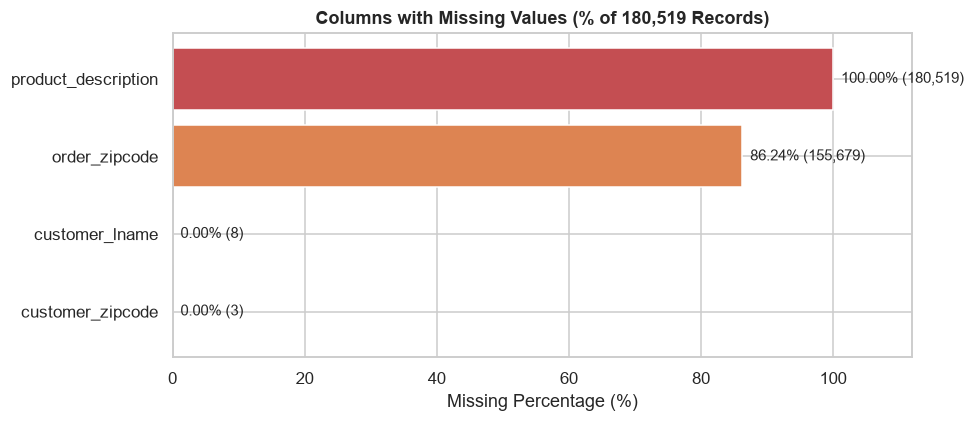

In [2]:
missing_counts = df.isna().sum()
missing_pct = (missing_counts / len(df)) * 100

missing_df = (
    pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing_count": missing_counts,
        "missing_pct": missing_pct.round(4),
        "non_null_count": df.notna().sum(),
        "n_unique": df.nunique(dropna=True),
    })
    .sort_values("missing_count", ascending=False)
)

print("Columns with missing values:")
display(missing_df[missing_df["missing_count"] > 0])

fig, ax = plt.subplots(figsize=(9, 4))
subset = missing_df[missing_df["missing_count"] > 0].sort_values("missing_pct", ascending=True)
bars = ax.barh(subset.index, subset["missing_pct"], color=["#4C72B0", "#4C72B0", "#DD8452", "#C44E52"])
ax.set_xlabel("Missing Percentage (%)")
ax.set_title("Columns with Missing Values (% of 180,519 Records)", fontweight="bold")
ax.set_xlim(0, 112)

for bar, (_, row) in zip(bars, subset.iterrows()):
    ax.text(
        bar.get_width() + 1.2,
        bar.get_y() + bar.get_height() / 2,
        f"{row['missing_pct']:.2f}% ({int(row['missing_count']):,})",
        va="center",
        fontsize=9.5,
    )

plt.tight_layout()
plt.show()

### Findings on Missing Values
Only **4 out of 54 columns** contain missing values:
- **`product_description`** (`100.00%` missing / `180,519` nulls): Completely empty across the entire dataset. **Action**: Drop column during preprocessing.
- **`order_zipcode`** (`86.24%` missing / `155,679` nulls): Mostly unpopulated (especially for international orders outside the US). **Action**: Drop column (or only use a binary `has_order_zipcode` indicator if informative, though `order_city` / `order_state` / `order_country` are 100% populated).
- **`customer_lname`** (`0.0044%` missing / `8` nulls) & **`customer_zipcode`** (`0.0017%` missing / `3` nulls): Negligible missingness on customer PII/address fields.

---
## 2. Evaluating Integer Columns: Quantities vs. Categories vs. Record Identifiers

In the raw CSV, 14 source columns (including the prediction target `days_for_shipping_real`) are stored as integers. However, not all integers represent numerical quantities where arithmetic operations (mean, standard deviation, linear correlation) are meaningful:

1. **Nominal Codes & Binary Flags -> `category` in `config.yaml`**:
   - `late_delivery_risk` (2 unique values: `0`, `1`): Binary indicator flag for whether delivery was late.
   - `category_id` (51 unique values) & `product_category_id` (51 unique values): Nominal product category codes.
   - `department_id` (11 unique values): Nominal store department codes (`2` to `12`).
   - `product_card_id` (118 unique values) & `order_item_cardprod_id` (118 unique values): Nominal product catalog codes.
   - `product_status` (1 unique value: `0`): Binary status code indicating product availability.
2. **High-Cardinality Entity / Transaction Identifiers -> `string` in `config.yaml`**:
   - `customer_id` (20,652 unique), `order_customer_id` (20,652 unique), `order_id` (65,752 unique), `order_item_id` (180,519 unique).
3. **True Quantitative Variables -> Retained as `int64`**:
   - `order_item_quantity` (1 to 5 units): Physical quantity ordered per basket line.
   - `days_for_shipment_scheduled` (0, 1, 2, 4 days): Promised delivery baseline based on shipping service tier.
   - `days_for_shipping_real` (0 to 6 days): Physical fulfillment and shipping duration from dispatch to delivery (**Target Parameter**).


In [3]:
integer_origin_cols = [
    "days_for_shipping_real",
    "days_for_shipment_scheduled",
    "order_item_quantity",
    "shipping_delay_days",
    "late_delivery_risk",
    "category_id",
    "product_category_id",
    "department_id",
    "product_card_id",
    "order_item_cardprod_id",
    "product_status",
    "customer_id",
    "order_customer_id",
    "order_id",
    "order_item_id",
]

int_eval_rows = []
for col in integer_origin_cols:
    s_num = pd.to_numeric(df[col].astype(str), errors="coerce")
    int_eval_rows.append({
        "column": col,
        "updated_yaml_dtype": str(df[col].dtype),
        "n_unique": df[col].nunique(),
        "min_val": int(s_num.min()),
        "max_val": int(s_num.max()),
        "sample_values": df[col].unique()[:5].tolist(),
        "semantic_role": (
            "Discrete Numeric Quantity" if str(df[col].dtype) == "int64"
            else ("Nominal Category / Flag" if str(df[col].dtype) == "category" else "Entity / Record ID")
        ),
    })

int_eval_df = pd.DataFrame(int_eval_rows)
display(int_eval_df)

,column,updated_yaml_dtype,n_unique,min_val,max_val,sample_values,semantic_role
0,days_for_shipping_real,int64,7,0,6,"[3, 5, 4, 2, 6]",Discrete Numeric Quantity
1,days_for_shipment_scheduled,int64,4,0,4,"[4, 1, 2, 0]",Discrete Numeric Quantity
2,order_item_quantity,int64,5,1,5,"[1, 2, 3, 5, 4]",Discrete Numeric Quantity
3,shipping_delay_days,int64,7,-2,4,"[-1, 1, 0, -2, 2]",Discrete Numeric Quantity
4,late_delivery_risk,category,2,0,1,"[0, 1]",Nominal Category / Flag
5,category_id,category,51,2,76,"[73, 17, 29, 24, 13]",Nominal Category / Flag
6,product_category_id,category,51,2,76,"[73, 17, 29, 24, 13]",Nominal Category / Flag
7,department_id,category,11,2,12,"[2, 4, 5, 3, 6]",Nominal Category / Flag
8,product_card_id,category,118,19,1363,"[1360, 365, 627, 502, 278]",Nominal Category / Flag
9,order_item_cardprod_id,category,118,19,1363,"[1360, 365, 627, 502, 278]",Nominal Category / Flag


In [4]:
# Summary of column counts by updated data type across the dataset
dtype_summary = df.dtypes.astype(str).value_counts().rename_axis("dtype").to_frame("column_count")
display(dtype_summary)

,column_count
dtype,
category,18
string,18
float64,12
int64,4
datetime64[us],2


---
## 3. Summary Statistics on Numerical Values

With non-quantitative IDs and nominal codes properly typed as `category` and `string`, we now have **16 true numerical columns** (`12 float64` + `4 int64`, including `shipping_delay_days`). Let's compute extended descriptive statistics including percentiles, interquartile range (IQR), skewness, and kurtosis.

In [5]:
num_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
print(f"Total numerical columns ({len(num_cols)}): {num_cols}")

desc = df[num_cols].describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).T
desc["IQR"] = desc["75%"] - desc["25%"]
desc["skewness"] = df[num_cols].skew()
desc["kurtosis"] = df[num_cols].kurtosis()
desc["n_zeros"] = (df[num_cols] == 0).sum()
desc["n_negative"] = (df[num_cols] < 0).sum()

cols_order = [
    "count", "mean", "std", "min", "1%", "5%", "25%", "50%", "75%", "95%", "99%", "max",
    "IQR", "skewness", "kurtosis", "n_zeros", "n_negative"
]
display(desc[cols_order].round(3))

Total numerical columns (16): ['days_for_shipping_real', 'days_for_shipment_scheduled', 'benefit_per_order', 'sales_per_customer', 'latitude', 'longitude', 'order_item_discount', 'order_item_discount_rate', 'order_item_product_price', 'order_item_profit_ratio', 'order_item_quantity', 'sales', 'order_item_total', 'order_profit_per_order', 'product_price', 'shipping_delay_days']


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,IQR,skewness,kurtosis,n_zeros,n_negative
days_for_shipping_real,180519.0,3.498,1.624,0.000,0.000,1.000,2.000,3.000,5.000,6.000,6.000,6.000,3.000,0.085,-1.008,5080,0
days_for_shipment_scheduled,180519.0,2.932,1.374,0.000,0.000,0.000,2.000,4.000,4.000,4.000,4.000,4.000,2.000,-0.732,-1.023,9737,0
benefit_per_order,180519.0,21.975,104.434,-4274.980,-415.599,-139.251,7.000,31.520,64.800,132.290,184.230,911.800,57.800,-4.742,71.377,1177,33784
sales_per_customer,180519.0,183.108,120.044,7.490,22.490,41.500,104.380,163.990,247.400,383.980,464.950,1939.990,143.020,2.888,23.920,0,0
latitude,180519.0,29.720,9.814,-33.938,18.201,18.213,18.265,33.145,39.280,42.391,45.359,48.782,21.014,-0.098,-1.555,0,9
longitude,180519.0,-84.916,21.433,-158.026,-123.032,-121.435,-98.446,-76.848,-66.371,-66.183,-66.025,115.263,32.076,-0.498,2.181,0,180414
order_item_discount,180519.0,20.665,21.801,0.000,0.000,0.000,5.400,14.000,29.990,62.500,95.860,500.000,24.590,3.040,25.231,10028,0
order_item_discount_rate,180519.0,0.102,0.070,0.000,0.000,0.000,0.040,0.100,0.160,0.250,0.250,0.250,0.120,0.341,-0.901,10028,0
order_item_product_price,180519.0,141.233,139.732,9.990,15.990,31.990,50.000,59.990,199.990,399.980,452.040,1999.990,149.990,3.191,23.313,0,0
order_item_profit_ratio,180519.0,0.121,0.467,-2.750,-1.750,-0.770,0.080,0.270,0.360,0.480,0.500,0.500,0.280,-2.894,10.157,1177,33784


---
## 4. Target Variable Distribution: Actual Transit Days (`days_for_shipping_real`)

The prediction target is defined as:
$$\text{target} = \text{days\_for\_shipping\_real}$$

Unlike delay residuals (which depend on operational quotes that shift when buffers are added), **actual shipping time** is an immutable physical measurement of fulfillment duration. It is strictly non-negative, taking discrete integer values from `0` to `6` days.


In [6]:
target_col = "days_for_shipping_real"
target_counts = df[target_col].value_counts().sort_index()
target_pct = (target_counts / len(df)) * 100
target_cdf = target_pct.cumsum()

target_summary = pd.DataFrame({
    "shipping_days": target_counts.index,
    "count": target_counts.values,
    "percentage (%)": target_pct.values.round(2),
    "cumulative_pct (%)": target_cdf.values.round(2),
}).set_index("shipping_days")

display(target_summary)


,status_bucket,count,percentage (%),cumulative_pct (%)
delay_days,,,,
-2,Early (< 0),21666,12.00,12.00
-1,Early (< 0),21700,12.02,24.02
0,On-Time (0),33753,18.70,42.72
1,Late (> 0),60647,33.60,76.32
2,Late (> 0),28718,15.91,92.23
3,Late (> 0),7052,3.91,96.13
4,Late (> 0),6983,3.87,100.00



Aggregated Delivery Timing Buckets:


,count,percentage (%)
status_bucket,,
Early (< 0),43366,24.02
On-Time (0),33753,18.70
Late (> 0),103400,57.29


findfont: Failed to find font weight semibold for Arial, now using 700.


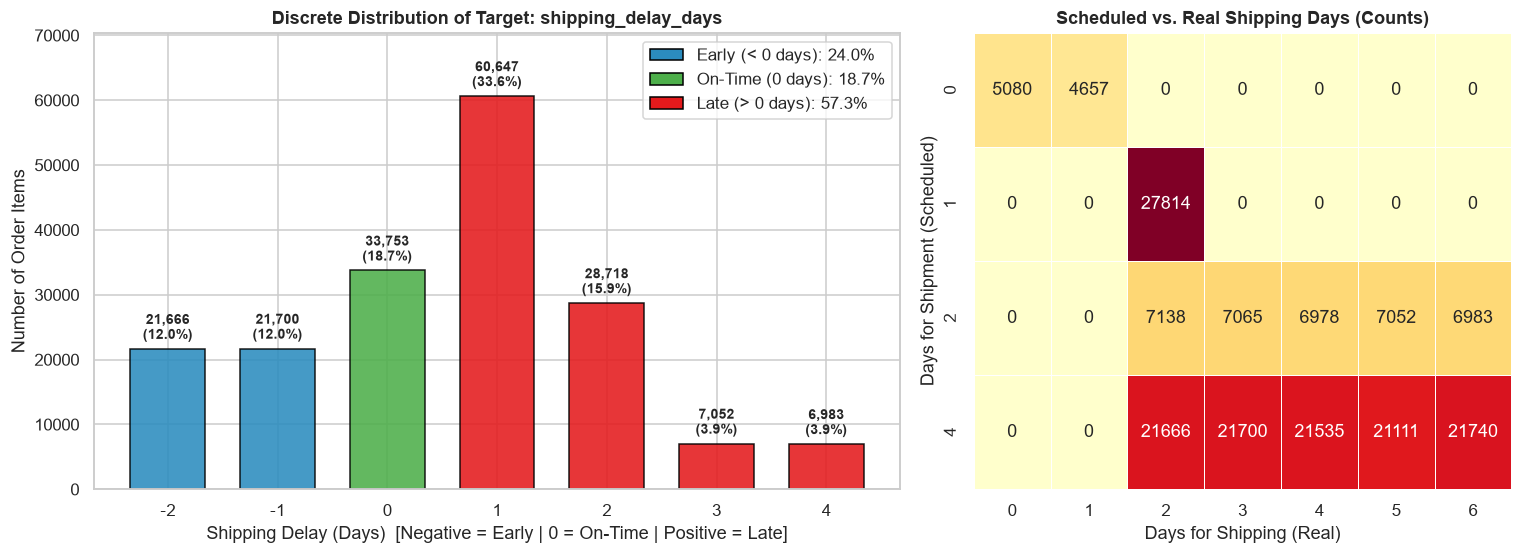

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.3, 1]})

# Left plot: Discrete PMF bar chart of actual shipping duration
colors = ["#2b83ba", "#74add1", "#abd9e9", "#fee090", "#fdae61", "#f46d43", "#d73027"]
bars = axes[0].bar(target_counts.index.astype(str), target_counts.values, color=colors, edgecolor="black", alpha=0.9, width=0.65)
axes[0].set_title("Distribution of Target: days_for_shipping_real", fontweight="bold", fontsize=12)
axes[0].set_xlabel("Actual Shipping Time (Days)", fontweight="bold")
axes[0].set_ylabel("Number of Order Items", fontweight="bold")
axes[0].set_ylim(0, target_counts.max() * 1.15)

for bar, pct in zip(bars, target_pct.values):
    h = bar.get_height()
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        h + 1000,
        f"{h:,}\n({pct:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="semibold",
    )

# Right plot: Shipping Mode vs. Real Shipping Days Contingency Heatmap
crosstab_mode = pd.crosstab(df["shipping_mode"], df["days_for_shipping_real"])
sns.heatmap(
    crosstab_mode,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    cbar=False,
    ax=axes[1],
    linewidths=0.5,
)
axes[1].set_title("Shipping Mode vs. Actual Shipping Days", fontweight="bold", fontsize=12)
axes[1].set_xlabel("Days for Shipping (Real)", fontweight="bold")
axes[1].set_ylabel("Shipping Mode", fontweight="bold")

plt.tight_layout()
plt.show()


### Key Insights on the Target Distribution (`days_for_shipping_real`)
1. **Discrete Support Across `{0, 1, 2, 3, 4, 5, 6}` Days**:
   - The target metric spans `0` to `6` integer days, with an overall mean of `3.50` days and median of `3.0` days.
   - `2 days` is the single most frequent duration (`56,618` orders, `31.36%`), largely because **all 27,814 First Class orders take exactly 2 days** and a substantial fraction of Second/Standard Class orders also arrive in 2 days.
2. **Fulfillment Mode Segmentation**:
   - **Same Day** (`9,737` orders): Takes strictly `0` days (`52.2%`) or `1` day (`47.8%`).
   - **First Class** (`27,814` orders): Deterministically takes exactly `2` days (`100.0%`).
   - **Second Class** (`35,216` orders): Uniformly distributed across `{2, 3, 4, 5, 6}` days (~`20%` / ~`7,000` orders each).
   - **Standard Class** (`107,752` orders): Uniformly distributed across `{2, 3, 4, 5, 6}` days (~`20%` / ~`21,500` orders each).
3. **Operational Advantage of Predicting Actual Days**:
   - Because actual shipping duration is strictly positive and decouples physical delivery speed from arbitrary scheduled quotes, predicting `P50` and `P90` of `days_for_shipping_real` eliminates policy feedback loops and enables dynamic delivery date quoting directly at checkout.
